# Modeling Compare — Boom-model vs Pitty-model vs Jack-model

วัด 3 โมเดล (Part Forward: วิดีโอภาษามือ → คำ) บนข้อมูลชุดเดียวกัน

| โมเดล | ที่เก็บ | ที่มา |
|---|---|---|
| **Boom-model** | `models/Boom-model/` | branch `boom` + ค่าตั้ง "Combined" ที่ Boom ล็อกไว้ (p_sign_min 0.55 · act_thr 0.6 · accept_min 0.7) |
| **Pitty-model** | `models/Pitty-model/` | branch `pitty` (p_sign_min 0.55 · min_hand_frac 0.3 · accept_min 0.7) |
| **Jack-model** | `models/Jack-model/` | branch `jack_master` v8.1 (merge/split ท่า · hand-shape cue · calibration ใหม่ · accept_min 0.8) |

**กติกาเดียวกันทุกโมเดล**: landmark (MediaPipe) ชุดเดียวกัน · vocab conversation · CPU + ONNX · ไม่ใช้ LLM · แต่ละโมเดลรันด้วยโค้ดของ branch ตัวเอง (คนละ process)

**ตัววัดหลัก**
* **WER** = (ผิด + ขาด + เกิน) / จำนวนคำเฉลย — ต่ำ = ดี
* **Recall@1 / @5** = คำเฉลยที่โมเดลอ่านถูก (ตรงตำแหน่ง) / อยู่ใน top-5 — สูง = ดี
* **Segment F1** = ตัดช่วงท่าตรงกับเฉลย (IoU ≥ 0.5) — เฉพาะ TSL51 ที่มีขอบเขตท่า
* **ยืนยัน (accepted)** = คำที่ระบบมั่นใจพอจะแสดง/พูด → precision (ถูกกี่ %) และ coverage (ได้กี่ % ของคำเฉลย)

In [1]:
import json, os, subprocess, sys
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / 'pitty/scripts')); from wer_ops import align      # WER alignment → C/S/D/I
E = ROOT / 'cache/modeling_compare'
MODELS = ['Boom-model', 'Pitty-model', 'Jack-model']
COL = {'Boom-model': '#2a78d6', 'Pitty-model': '#eb6834', 'Jack-model': '#1baf7a'}
plt.rcParams.update({'font.family': ['Leelawadee UI', 'Tahoma', 'sans-serif'], 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.edgecolor': '#898781', 'axes.labelcolor': '#52514e', 'xtick.color': '#52514e', 'ytick.color': '#52514e',
                     'axes.facecolor': '#fcfcfb', 'figure.facecolor': '#fcfcfb'})
pd.set_option('display.max_colwidth', 70); pd.set_option('display.width', 250)

RERUN = False      # True = รันโมเดลใหม่ทั้งหมด · False = ใช้ผลใน cache/modeling_compare/results ถ้ามีแล้ว
def run(*args):
    p = subprocess.run([sys.executable, 'scripts/modeling_compare.py', *args], cwd=ROOT, capture_output=True, text=True,
                       encoding='utf-8', env=dict(os.environ, PYTHONIOENCODING='utf-8'))
    assert p.returncode == 0, p.stderr[-2000:]

run('setup')       # models/<name>/ + โค้ด branch pitty / boom (ข้ามถ้ามีแล้ว)
run('extract')     # MediaPipe ของวิดีโอ team-drive (ครั้งเดียว)
for s in ['tsl51', 'team']:
    for m in MODELS:
        if RERUN or not (E / f'results/{m}__{s}.json').exists():
            print('run', m, s); run('eval', '--model', m, '--set', s)
R = {(m, s): json.loads((E / f'results/{m}__{s}.json').read_text(encoding='utf-8')) for m in MODELS for s in ['tsl51', 'team']}
pd.DataFrame({m: R[(m, 'team')]['card'] for m in MODELS}).T[['branch', 'commit', 'setting']]

,branch,commit,setting
Boom-model,origin/boom,04cc177899dda09e0d04260bd2eda7c67113c543,"{'conversation.post.p_sign_min': 0.55, 'conversation.act_thr': 0.6..."
Pitty-model,origin/pitty,4aeb7b9ab0ae9a2f1c0b9aab9e0c8664322852cf,branch models/spotting.json as is
Jack-model,jack_master,c6a1cfe71f07bd5f845f199a89cb6010029cb283,branch models/spotting.json as is


In [2]:
def iou(a, b):
    i = max(0, min(a[1], b[1]) - max(a[0], b[0])); u = max(a[1], b[1]) - min(a[0], b[0])
    return i / u if u > 0 else 0.0

def score(it, vocab):
    """หนึ่งคลิป → นับ ถูก/ผิด/ขาด/เกิน จาก WER alignment + recall@5 + คำที่ยืนยัน + Segment F1 (ถ้ามีขอบเขตเฉลย)"""
    ref, segs = it['ref'], it['segs']; hyp = [s['word'] for s in segs]
    ops = align(ref, hyp); c = {k: sum(o[0] == k for o in ops) for k in 'CSDI'}
    ok = {o[3] for o in ops if o[0] == 'C'}                            # ตำแหน่ง hyp ที่ถูก
    acc = [j for j, s in enumerate(segs) if s['status'] == 'accepted']
    row = dict(n_ref=len(ref), n_hyp=len(hyp), right=c['C'], wrong=c['S'], missing=c['D'], extra=c['I'],
               WER=(c['S'] + c['D'] + c['I']) / len(ref), top5=sum(o[0] in 'CS' and o[1] in segs[o[3]]['top5'] for o in ops),
               acc=len(acc), acc_ok=sum(j in ok for j in acc), oov=sum(w not in vocab for w in ref), latency=it['latency_s'],
               ref_txt=' '.join(ref), hyp_txt=' '.join(hyp))
    if it.get('gold'):                                                 # Segment F1: จับคู่ IoU ≥ 0.5 แบบ 1-ต่อ-1
        used, tp = set(), 0
        for s in segs:
            j = max(range(len(it['gold'])), key=lambda k: -1 if k in used else iou((s['f0'], s['f1']), it['gold'][k]))
            if j not in used and iou((s['f0'], s['f1']), it['gold'][j]) >= 0.5:
                used.add(j); tp += 1
        row.update(seg_tp=tp, n_gold=len(it['gold']))
    return row

def per_item(s):
    out = []
    for m in MODELS:
        r = R[(m, s)]; voc = set(r['vocab']) | {chr(c) for c in range(65, 91)}       # คำใน vocab + ตัวอักษร A–Z (สะกดนิ้ว)
        out += [dict(model=m, id=it['id'], person=it.get('person', ''), **score(it, voc)) for it in r['items']]
    return pd.DataFrame(out)

def summary(df):
    """รวมทุกคลิปของแต่ละโมเดล"""
    def f(x):
        n = x.n_ref.sum()
        d = {'คลิป': len(x), 'WER (เฉลี่ยต่อคลิป)': x.WER.mean(), 'WER (รวมทุกคำ)': (x.wrong + x.missing + x.extra).sum() / n,
             'ถูก': x.right.sum(), 'ผิด': x.wrong.sum(), 'ขาด': x.missing.sum(), 'เกิน': x.extra.sum(),
             'Recall@1': x.right.sum() / n, 'Recall@5': x.top5.sum() / n,
             'ยืนยัน precision': x.acc_ok.sum() / max(x.acc.sum(), 1), 'ยืนยัน coverage': x.acc_ok.sum() / n,
             'ยืนยัน (ถูก/ทั้งหมด)': f"{x.acc_ok.sum()}/{x.acc.sum()}", 'count error': (x.n_hyp - x.n_ref).abs().mean(),
             'latency (s, median)': x.latency.median()}
        if 'seg_tp' in x:
            p, r_ = x.seg_tp.sum() / max(x.n_hyp.sum(), 1), x.seg_tp.sum() / x.n_gold.sum()
            d['Segment F1'] = 2 * p * r_ / max(p + r_, 1e-9)
        return pd.Series(d)
    return df.groupby('model', sort=False)[df.columns.drop('model')].apply(f).reindex(MODELS)

fmt3 = lambda t: t.style.format({c: '{:.3f}' for c in t.columns if t[c].dtype == float}).highlight_min(
    subset=[c for c in t.columns if c.startswith('WER') or c == 'count error'], color='#dcfce7').highlight_max(
    subset=[c for c in t.columns if c.startswith(('Recall', 'Segment', 'ยืนยัน p', 'ยืนยัน c'))], color='#dcfce7')

def bars(ax, t, metric, title, lower_better):
    v = t[metric].astype(float)
    ax.bar(v.index, v.values, color=[COL[m] for m in v.index], width=0.6, edgecolor='#fcfcfb', linewidth=2)
    for i, x in enumerate(v.values):
        ax.text(i, x + v.max() * 0.02, f'{x:.3f}', ha='center', fontsize=10, color='#0b0b0b')
    ax.set_title(f"{title} ({'ต่ำ' if lower_better else 'สูง'} = ดี)", fontsize=11); ax.set_ylim(0, v.max() * 1.18)
    ax.grid(axis='y', color='#e1e0d9', lw=0.6); ax.set_axisbelow(True); ax.tick_params(axis='x', labelsize=9)

---
## 1. TSL51 (ชุดปกติ)

TSL51 `sentence_test` = **126 ประโยค** ของผู้วิจัย TSL51 (ประโยค template ที่ไม่ได้ใช้เทรน tagger) ความเร็วปกติ 1×
* bank = `artifacts/eval/bank_eval.npz` (คลิปของผู้ทำท่าที่ใช้เทรนเท่านั้น → ไม่มีท่าของคนในชุดทดสอบใน bank)
* ปิดการสะกดนิ้ว (TSL51 ไม่มีตัวอักษร) · มีขอบเขตท่าเฉลย → คำนวณ Segment F1 ได้

In [3]:
T = per_item('tsl51')
ST = summary(T)
fmt3(ST)

,คลิป,WER (เฉลี่ยต่อคลิป),WER (รวมทุกคำ),ถูก,ผิด,ขาด,เกิน,Recall@1,Recall@5,ยืนยัน precision,ยืนยัน coverage,ยืนยัน (ถูก/ทั้งหมด),count error,"latency (s, median)",Segment F1
model,,,,,,,,,,,,,,,
Boom-model,126,0.431,0.447,291,153,6,42,0.647,0.842,0.878,0.271,122/139,0.381,0.776,0.731
Pitty-model,126,0.433,0.449,291,151,8,43,0.647,0.836,0.878,0.271,122/139,0.405,0.885,0.725
Jack-model,126,0.310,0.318,334,100,16,27,0.742,0.893,0.989,0.202,91/92,0.325,0.951,0.749


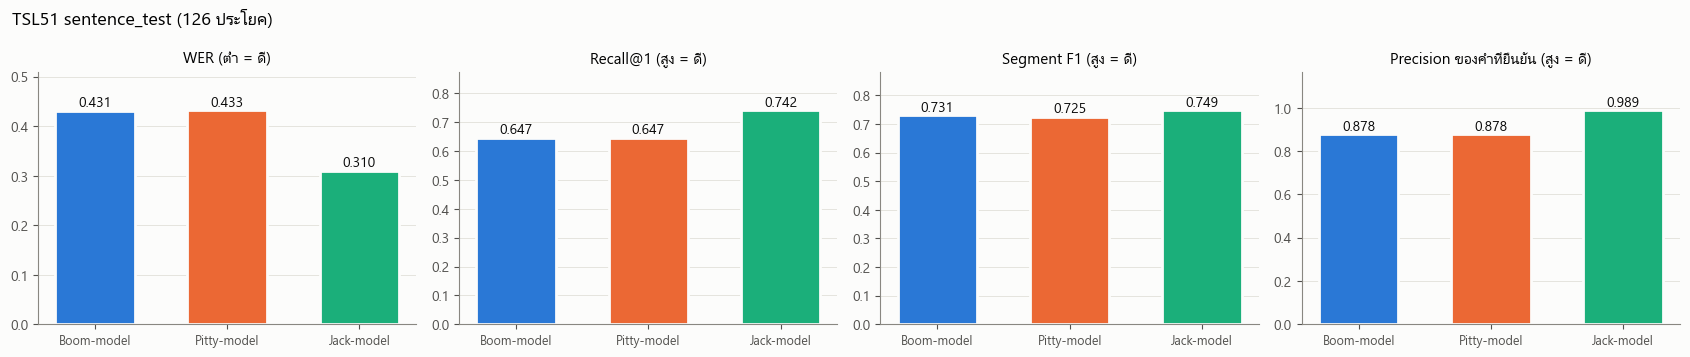

In [4]:
fig, ax = plt.subplots(1, 4, figsize=(17, 3.6))
for a, (m, t, lb) in zip(ax, [('WER (เฉลี่ยต่อคลิป)', 'WER', True), ('Recall@1', 'Recall@1', False),
                              ('Segment F1', 'Segment F1', False), ('ยืนยัน precision', 'Precision ของคำที่ยืนยัน', False)]):
    bars(a, ST, m, t, lb)
fig.suptitle('TSL51 sentence_test (126 ประโยค)', x=0.01, ha='left', fontsize=13); plt.tight_layout(); plt.show()

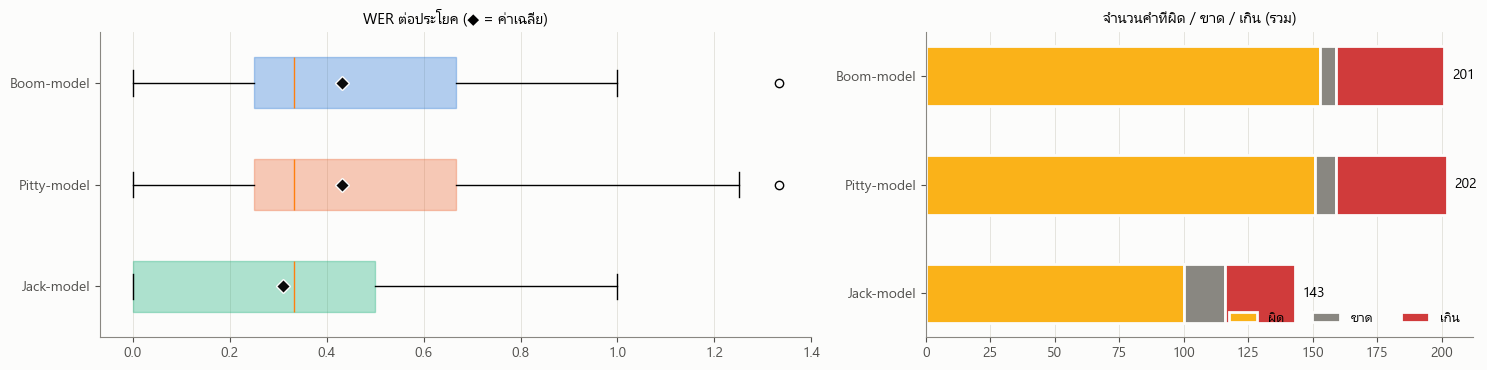

In [5]:
# การกระจายของ WER ต่อประโยค + ชนิดความผิดพลาดรวม
fig, ax = plt.subplots(1, 2, figsize=(15, 3.8), gridspec_kw={'width_ratios': [1.3, 1]})
bp = ax[0].boxplot([T[T.model == m].WER for m in MODELS], tick_labels=MODELS, vert=False, widths=0.5, patch_artist=True, showmeans=True,
                   meanprops=dict(marker='D', markerfacecolor='#0b0b0b', markeredgecolor='#fcfcfb', markersize=7))
for p, m in zip(bp['boxes'], MODELS):
    p.set(facecolor=COL[m], alpha=0.35, edgecolor=COL[m])
ax[0].set_title('WER ต่อประโยค (◆ = ค่าเฉลี่ย)', fontsize=11); ax[0].grid(axis='x', color='#e1e0d9', lw=0.6); ax[0].invert_yaxis()
e = ST[['ผิด', 'ขาด', 'เกิน']].astype(int)
left = np.zeros(len(e))
for k, c in zip(e.columns, ['#fab219', '#898781', '#d03b3b']):
    ax[1].barh(e.index, e[k], left=left, color=c, label=k, height=0.55, edgecolor='#fcfcfb', linewidth=2); left += e[k].values
for i, v in enumerate(left):
    ax[1].text(v + 3, i, int(v), va='center', fontsize=10)
ax[1].invert_yaxis(); ax[1].legend(ncol=3, frameon=False, loc='lower right'); ax[1].set_title('จำนวนคำที่ผิด / ขาด / เกิน (รวม)', fontsize=11)
ax[1].grid(axis='x', color='#e1e0d9', lw=0.6); ax[1].set_axisbelow(True)
plt.tight_layout(); plt.show()

In [6]:
# ประโยคที่ 3 โมเดลอ่านต่างกันมากที่สุด (ตัวอย่าง 8 ประโยค)
P = T.pivot(index='id', columns='model', values='WER')[MODELS]
ex = P.assign(spread=P.max(1) - P.min(1)).sort_values('spread', ascending=False).head(8).index
H = T.set_index(['id', 'model']).hyp_txt.unstack()[MODELS]
H.insert(0, 'เฉลย', T.drop_duplicates('id').set_index('id').ref_txt)
H.loc[ex]

model,เฉลย,Boom-model,Pitty-model,Jack-model
id,,,,
t51s:กรุงเทพ_var_1__ฉัน_var_2__เที่ยว_var_1__ชอบ_var_1_no_space_3,กรุงเทพ ฉัน เที่ยว ชอบ,กรุงเทพ ผอม ฉัน หนึ่ง ฉัน,กรุงเทพ ผอม โสด ที่ไหน หนึ่ง ฉัน,กรุงเทพ โสด หนึ่ง ชอบ
t51s:แฟน_var_1__ข้าว_var_1__กิน_var_1_no_space_1,แฟน ข้าว กิน,แฟน ชอบ ไม่มี เท่าไร ดู,แฟน ชอบ ไม่มี เท่าไร ดู,แฟน ข้าว เท่าไร ดู
t51s:พรุ่งนี้_var_1__คุณ_var_1__ข้าว_var_1__กิน_var_1__ไป_var_2__ที่ไหน_var_1_no_space_2,พรุ่งนี้ คุณ ข้าว กิน ไป ที่ไหน,พ่อ หนึ่ง ไม่มี ดู กลับ ที่ไหน,พ่อ หนึ่ง ไม่มี ดู กลับ ที่ไหน,พรุ่งนี้ คุณ ข้าว ดู กลับ ที่ไหน
t51s:วันนี้_var_1__คุณ_var_1__ข้าว_var_1__กิน_var_1__ไป_var_2__ที่ไหน_var_1_no_space_0,วันนี้ คุณ ข้าว กิน ไป ที่ไหน,วันนี้ ต้อง ไม่มี ผอม กลับ ที่ไหน,วันนี้ ต้อง ไม่มี ผอม กลับ ที่ไหน,วันนี้ คุณ ข้าว กิน กลับ ที่ไหน
t51s:ไข่_var_2__คุณ_var_1__กิน_var_1__ชอบ_var_1_no_space_1,ไข่ คุณ กิน ชอบ,ไข่ หนึ่ง ดู ชอบ ฉัน,ไข่ หนึ่ง ดู ชอบ ฉัน,ไข่ คุณ ดู ชอบ
t51s:ภาษามือ_var_1__แฟน_var_1__เรียน_var_1__ชอบ_var_1_no_space_2,ภาษามือ แฟน เรียน ชอบ,วิ่ง แฟน เรียน ชอบ ฉัน,วิ่ง แฟน เรียน ชอบ ฉัน,ภาษามือ แฟน เรียน ชอบ
t51s:ภาษามือ_var_1__แฟน_var_1__เรียน_var_1__ชอบ_var_1_no_space_1,ภาษามือ แฟน เรียน ชอบ,วิ่ง แฟน เรียน ชอบ ฉัน,วิ่ง แฟน เรียน ชอบ ฉัน,ภาษามือ แฟน เรียน ชอบ
t51s:กรุงเทพ_var_1__แฟน_var_1__เที่ยว_var_1__ชอบ_var_1_no_space_3,กรุงเทพ แฟน เที่ยว ชอบ,ลูก อยาก ที่ไหน หนึ่ง ชอบ,ลูก อยาก ที่ไหน หนึ่ง ชอบ,กรุงเทพ แฟน ที่ไหน หนึ่ง ชอบ


---
## 2. team-drive (วิดีโอจริงของทีม)

`data_test/team-drive/Eval-Test/` — **Pitty 7 · Boom 6 · Jack 5 = 18 คลิป** ถ่ายเองด้วยมือถือ (คนทำท่าไม่อยู่ในข้อมูลเทรน)
* bank = `bank.npz` ของแต่ละโมเดล (เหมือนตอนใช้งานจริง) · เปิดสะกดนิ้วภาษาอังกฤษ (ค่า default ของเว็บ; คลิปมี P / J / A I)
* เฉลย: Pitty / Boom จาก `pitty/team_compare/refs.csv` (Boom ตัดคำจากชื่อไฟล์ — ยังไม่ได้ยืนยันลำดับท่า) ·
  Jack = ลำดับท่าที่เจ้าของคลิปให้ไว้ (`modules/lexicon.py` IPHONE_TEST_REFS)
* `คำนอก vocab` = คำเฉลยที่โมเดลนั้นไม่รู้จักเลย (เช่น ไหม จะ กัน แอบ) → ไม่มีทางทายถูก

In [7]:
V = per_item('team')
SV = summary(V)
SV.insert(1, 'คำเฉลย', V.groupby('model').n_ref.sum()); SV.insert(2, 'คำนอก vocab', V.groupby('model').oov.sum())
display(Markdown('**รวม 18 คลิป**')); display(fmt3(SV))
SP = pd.concat({p: summary(V[V.person == p]) for p in ['Pitty', 'Boom', 'Jack']})
display(Markdown('**แยกตามคนที่ถ่ายคลิป**'))
fmt3(SP[['คลิป', 'WER (เฉลี่ยต่อคลิป)', 'Recall@1', 'Recall@5', 'ถูก', 'ผิด', 'ขาด', 'เกิน', 'ยืนยัน (ถูก/ทั้งหมด)', 'count error']])

**รวม 18 คลิป**

,คลิป,คำเฉลย,คำนอก vocab,WER (เฉลี่ยต่อคลิป),WER (รวมทุกคำ),ถูก,ผิด,ขาด,เกิน,Recall@1,Recall@5,ยืนยัน precision,ยืนยัน coverage,ยืนยัน (ถูก/ทั้งหมด),count error,"latency (s, median)"
model,,,,,,,,,,,,,,,,
Boom-model,18,85,10,0.853,0.847,39,42,4,26,0.459,0.541,0.800,0.141,12/15,1.667,1.216
Pitty-model,18,85,10,0.853,0.847,39,42,4,26,0.459,0.541,0.875,0.165,14/16,1.667,1.196
Jack-model,18,85,8,0.795,0.776,45,34,6,26,0.529,0.576,0.875,0.165,14/16,1.667,1.401


**แยกตามคนที่ถ่ายคลิป**

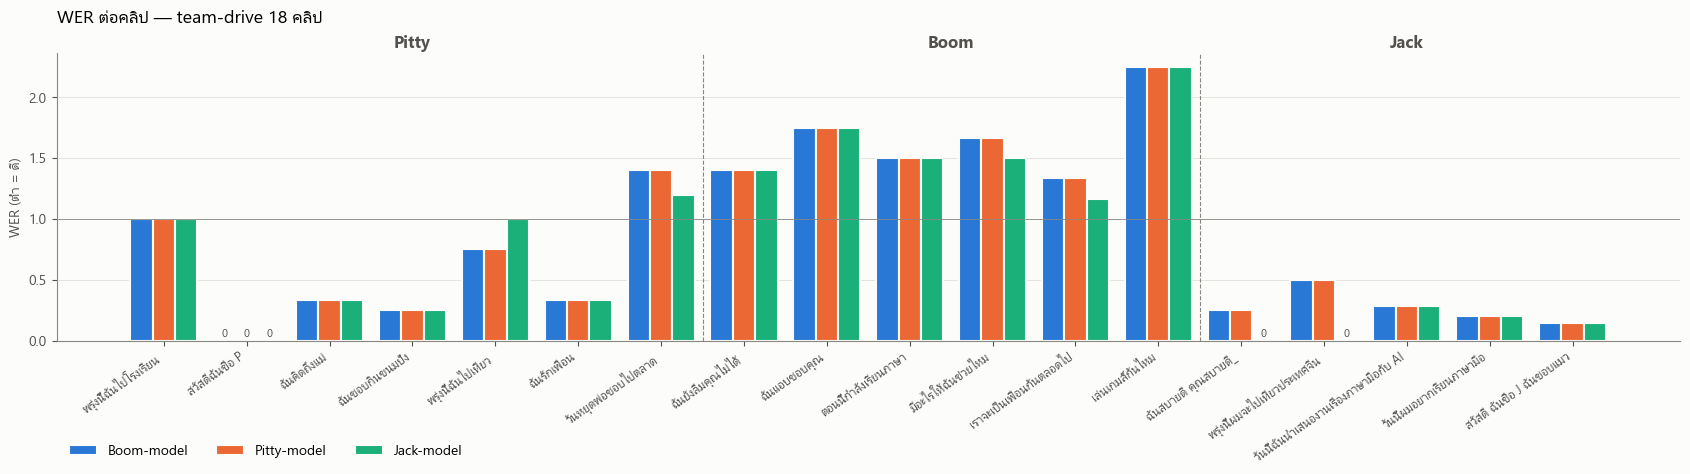

In [8]:
# WER ทุกคลิป × 3 โมเดล
order = V.drop_duplicates('id')[['id', 'person']]
fig, ax = plt.subplots(figsize=(17, 5.2))
x = np.arange(len(order)); w = 0.27
for k, m in enumerate(MODELS):
    v = V[V.model == m].set_index('id').WER.reindex(order.id)
    ax.bar(x + (k - 1) * w, v.values, w, color=COL[m], label=m, edgecolor='#fcfcfb', linewidth=1.5)
    for xi in np.flatnonzero(v.values == 0):                 # WER 0 = อ่านถูกทั้งประโยค (แท่งสูง 0)
        ax.text(x[xi] + (k - 1) * w, 0.03, '0', ha='center', fontsize=8, color='#52514e')
ax.set_xticks(x); ax.set_xticklabels([i.split('/')[1] for i in order.id], rotation=35, ha='right', fontsize=9)
for p in ['Pitty', 'Boom', 'Jack']:                     # แบ่งกลุ่มตามคนถ่าย
    idx = np.flatnonzero(order.person.values == p)
    ax.text(idx.mean(), ax.get_ylim()[1] * 1.02, p, ha='center', fontsize=12, fontweight='bold', color='#52514e')
    if idx[0] > 0: ax.axvline(idx[0] - 0.5, color='#898781', lw=0.8, ls='--')
ax.axhline(1, color='#898781', lw=0.6); ax.set_ylabel('WER (ต่ำ = ดี)')
ax.grid(axis='y', color='#e1e0d9', lw=0.6); ax.set_axisbelow(True); ax.legend(frameon=False, ncol=3, loc='upper left', bbox_to_anchor=(0, -0.32))
ax.set_title('WER ต่อคลิป — team-drive 18 คลิป', loc='left', fontsize=13, pad=22); plt.tight_layout(); plt.show()

In [9]:
# ตารางต่อคลิป: เฉลย vs คำที่แต่ละโมเดลอ่านได้ (top-1) + WER
tab = V.pivot(index='id', columns='model', values='hyp_txt')[MODELS].reindex(order.id)
w_ = V.pivot(index='id', columns='model', values='WER')[MODELS].reindex(order.id).round(2)
out = pd.DataFrame({'เฉลย': V.drop_duplicates('id').set_index('id').ref_txt.reindex(order.id)})
for m in MODELS:
    out[m] = tab[m]; out[f'WER {m.split("-")[0]}'] = w_[m]
out

,เฉลย,Boom-model,WER Boom,Pitty-model,WER Pitty,Jack-model,WER Jack
id,,,,,,,
Pitty/พรุ่งนี้ฉันไปโรงเรียน,พรุ่งนี้ ฉัน ไป โรงเรียน,แฟน สวัสดี ฉัน ยาย โรงเรียน ข้าว,1.00,แฟน สวัสดี ฉัน ยาย โรงเรียน ข้าว,1.00,แฟน สวัสดี ฉัน ยาย โรงเรียน น้อง,1.00
Pitty/สวัสดีฉันชื่อ P,สวัสดี ฉัน ชื่อ P,สวัสดี ฉัน ชื่อ P,0.00,สวัสดี ฉัน ชื่อ P,0.00,สวัสดี ฉัน ชื่อ P,0.00
Pitty/ฉันคิดถึงแม่,ฉัน คิดถึง แม่,ฉัน แม่,0.33,ฉัน แม่,0.33,ฉัน แม่,0.33
Pitty/ฉันชอบกินขนมปัง,ฉัน ชอบ กิน ขนมปัง,ฉัน กิน ขนมปัง,0.25,ฉัน กิน ขนมปัง,0.25,ฉัน กิน ขนมปัง,0.25
Pitty/พรุ่งนี้ฉันไปเที่ยว,พรุ่งนี้ ฉัน ไป เที่ยว,น้อง เที่ยว,0.75,น้อง เที่ยว,0.75,น้องชาย เที่ยว ที่ไหน,1.00
Pitty/ฉันรักเพื่อน,ฉัน รัก เพื่อน,ฉัน เกิด เพื่อน,0.33,ฉัน เกิด เพื่อน,0.33,ฉัน เพื่อน,0.33
Pitty/วันหยุดพ่อชอบไปตลาด,วันหยุด พ่อ ชอบ ไป ตลาด,เที่ยว ไป กิน ฉัน เพื่อน แม่ ขนมปัง,1.40,เที่ยว ไป กิน ฉัน เพื่อน แม่ ขนมปัง,1.40,วัน ไป กิน ชอบ เพื่อน แม่ ขนมปัง,1.20
Boom/ฉันยังลืมคุณไม่ได้,ฉัน ยัง ลืม คุณ ไม่ได้,ยาย ไป คุณ ชอบ ญาติ เป็น อย่า,1.40,ยาย ไป คุณ ชอบ ญาติ เป็น อย่า,1.40,ยาย โกรธ อย่า ชอบ ญาติ ไป อย่า,1.40
Boom/ฉันแอบชอบคุณ,ฉัน แอบ ชอบ คุณ,แฟน แต่งงาน เกิด แต่งงาน เกิด ข้าว ถาม,1.75,แฟน แต่งงาน เกิด แต่งงาน เกิด ข้าว ถาม,1.75,พ่อ แต่งงาน เกิด เป็น แต่งงาน เกิด น้องสาว คุณ,1.75


### Timeline ทุกคลิป × 3 โมเดล

แต่ละคลิป = 3 แถว (Boom / Pitty / Jack) แกน x = เวลา (วินาที) · แต่ละกล่อง = ท่าที่โมเดลตัดได้ + คำที่อ่าน
**สี = ผลเทียบเฉลย**: 🟩 ถูก · 🟨 ผิดคำ · 🟥 เกิน (ไม่มีในเฉลย) · ขอบหนา = คำที่ระบบ "ยืนยัน" · ท้ายแถวบอกคำที่ **ขาด**

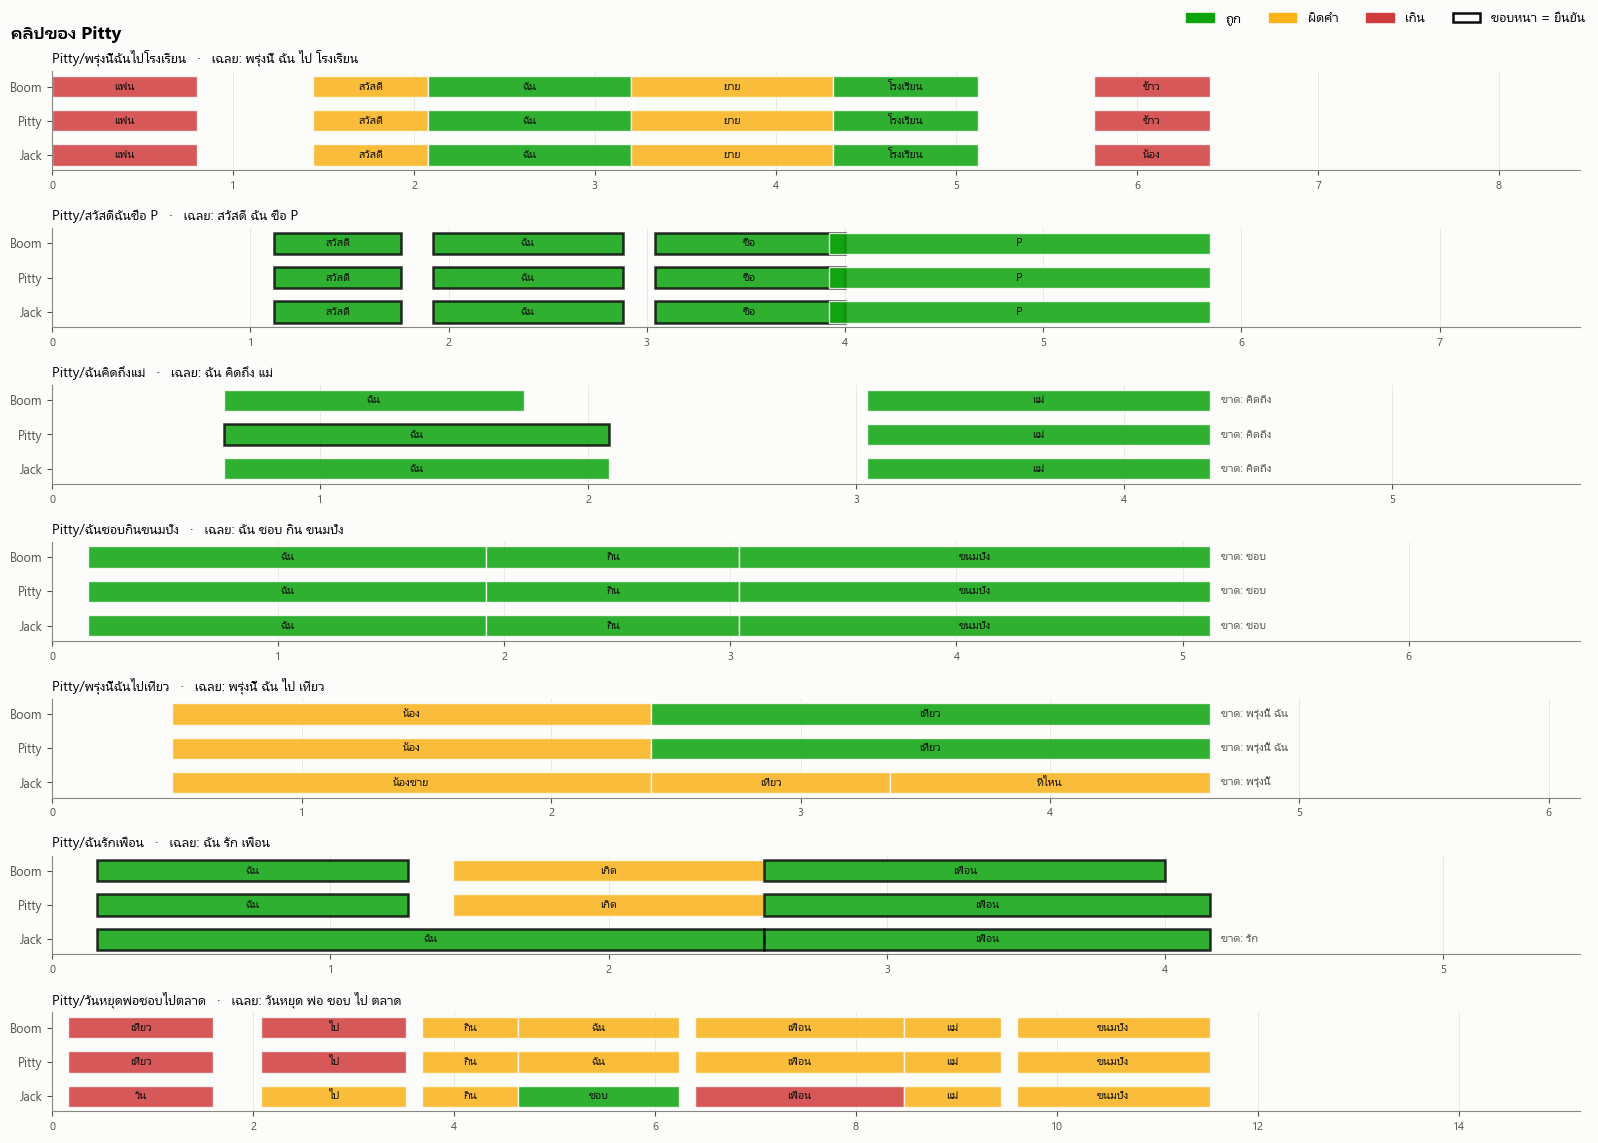

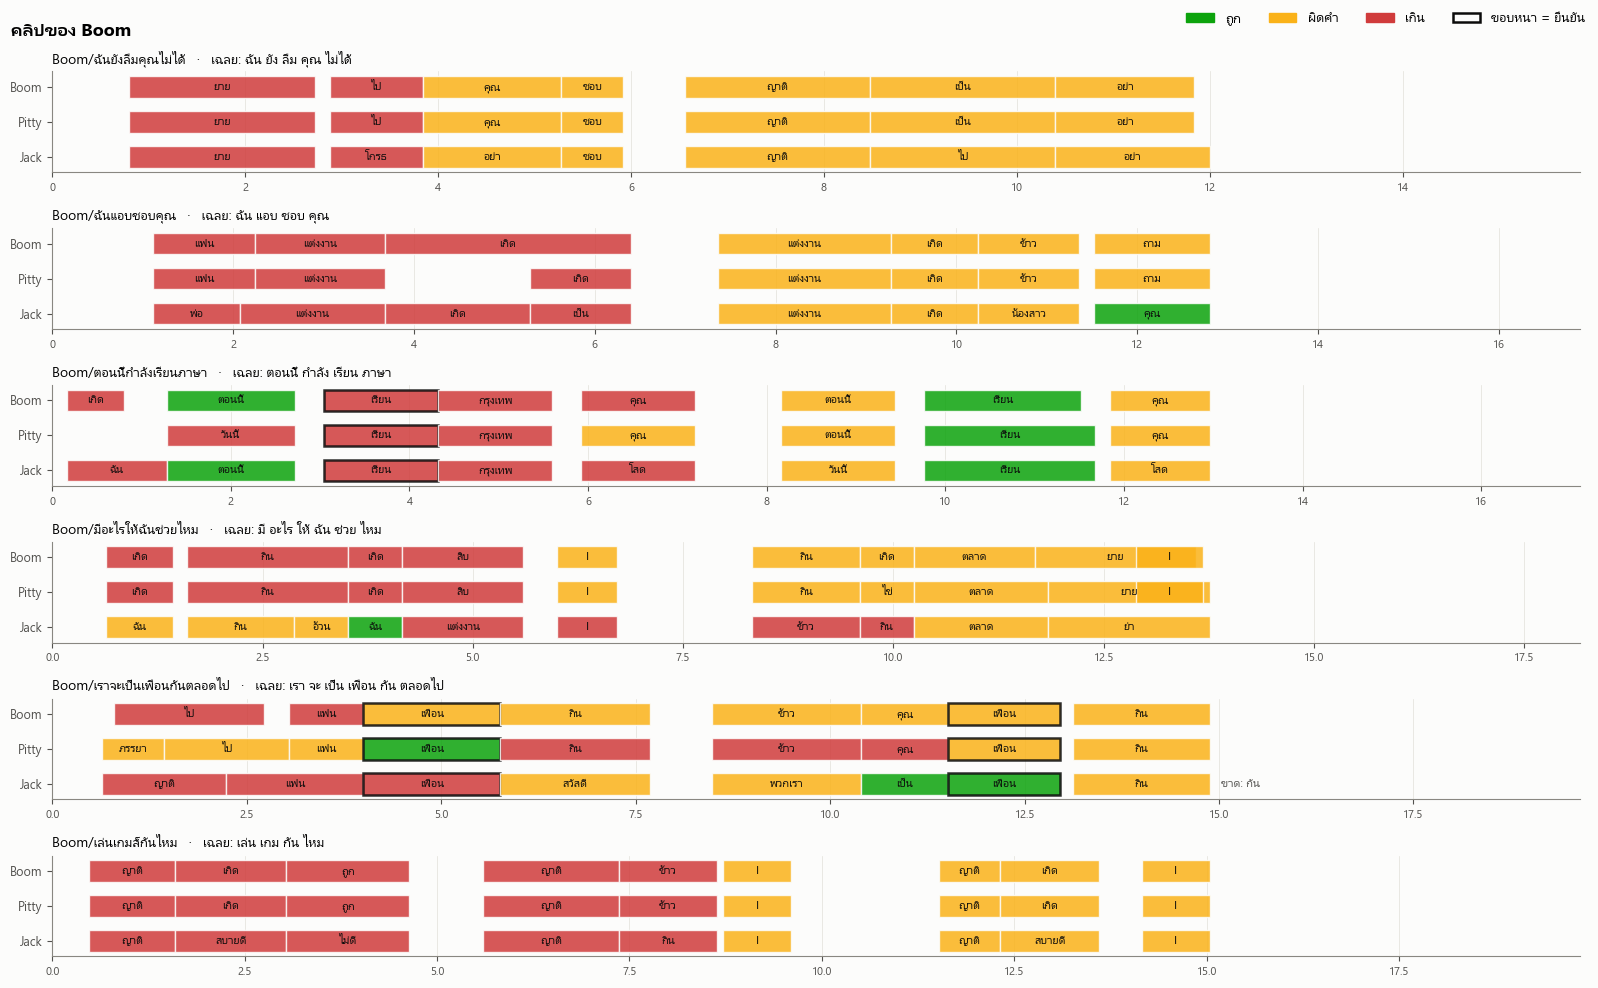

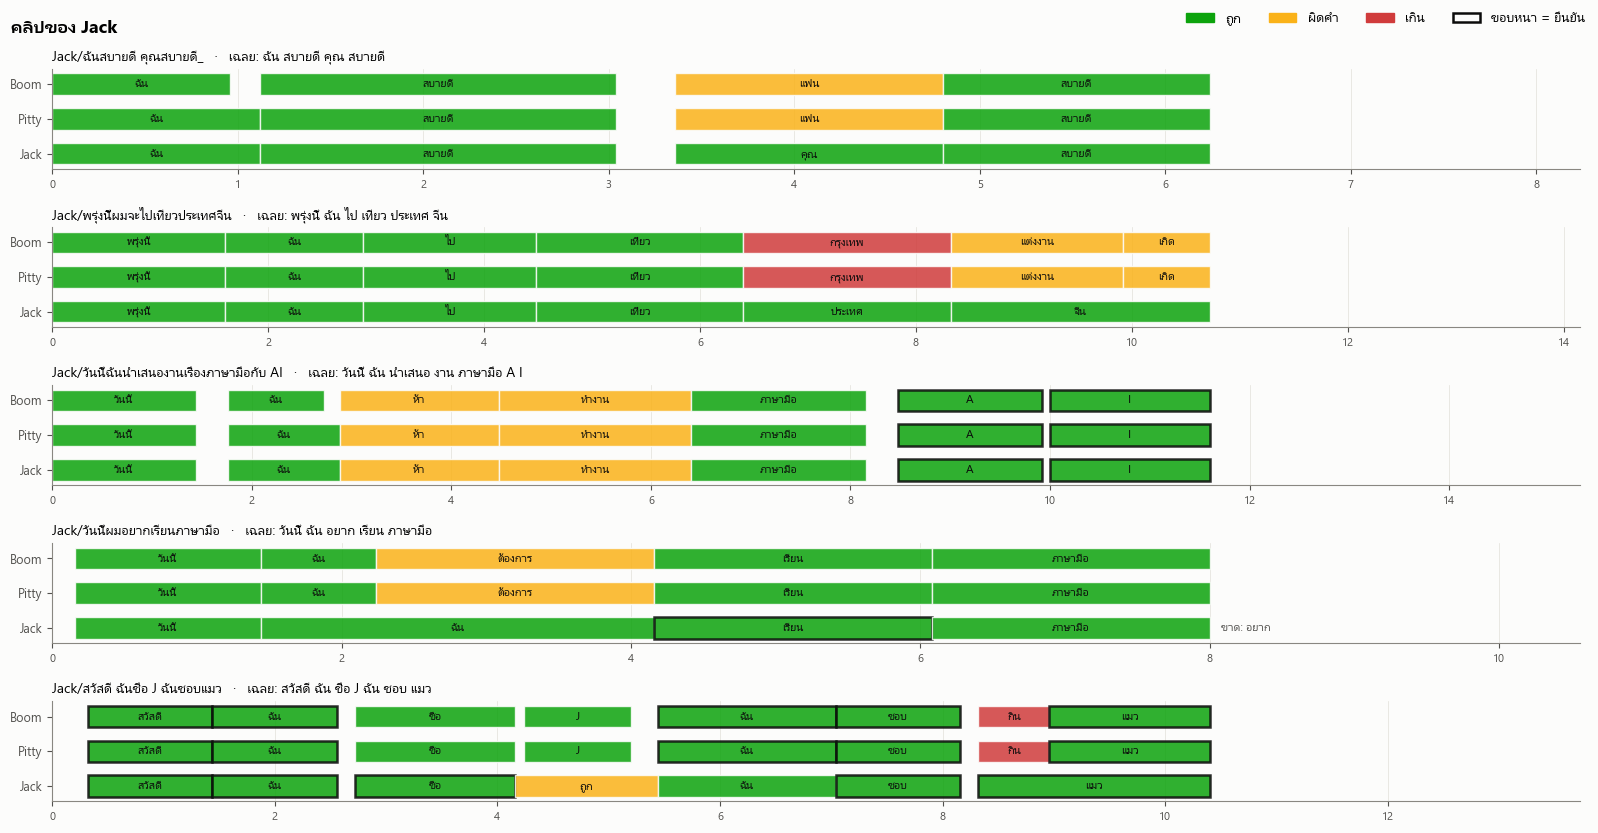

In [10]:
OPC = {'C': '#0ca30c', 'S': '#fab219', 'I': '#d03b3b'}
items = {(m, it['id']): it for m in MODELS for it in R[(m, 'team')]['items']}

def timeline(ax, vid):
    it0 = items[(MODELS[0], vid)]; ref = it0['ref']
    tmax = max([s['t1'] for m in MODELS for s in items[(m, vid)]['segs']] + [1])
    for row, m in enumerate(MODELS):
        segs = items[(m, vid)]['segs']; ops = align(ref, [s['word'] for s in segs])
        kind = {o[3]: o[0] for o in ops if o[3] is not None}
        for j, s in enumerate(segs):
            acc = s['status'] == 'accepted'
            ax.barh(row, s['t1'] - s['t0'], left=s['t0'], height=0.62, color=OPC[kind[j]], alpha=0.85,
                    edgecolor='#0b0b0b' if acc else '#fcfcfb', linewidth=1.8 if acc else 1)
            ax.text((s['t0'] + s['t1']) / 2, row, s['word'], ha='center', va='center', fontsize=8.5, color='#0b0b0b')
        miss = [o[1] for o in ops if o[0] == 'D']
        ax.text(tmax * 1.01, row, ('ขาด: ' + ' '.join(miss)) if miss else '', va='center', fontsize=8.5, color='#52514e')
    ax.set_yticks(range(3)); ax.set_yticklabels([m.split('-')[0] for m in MODELS], fontsize=9); ax.invert_yaxis()
    ax.set_xlim(0, tmax * 1.32); ax.grid(axis='x', color='#e1e0d9', lw=0.5); ax.set_axisbelow(True); ax.tick_params(axis='x', labelsize=8)
    ax.set_title(f"{vid}   ·   เฉลย: {' '.join(ref)}", loc='left', fontsize=10)

for p in ['Pitty', 'Boom', 'Jack']:
    vids = list(order[order.person == p].id)
    fig, axs = plt.subplots(len(vids), 1, figsize=(16, 1.55 * len(vids) + 0.6))
    for a, v in zip(np.atleast_1d(axs), vids):
        timeline(a, v)
    from matplotlib.patches import Patch
    fig.legend(handles=[Patch(color=OPC['C'], label='ถูก'), Patch(color=OPC['S'], label='ผิดคำ'), Patch(color=OPC['I'], label='เกิน'),
                        Patch(facecolor='none', edgecolor='#0b0b0b', lw=1.8, label='ขอบหนา = ยืนยัน')], ncol=4, frameon=False, loc='upper right')
    fig.suptitle(f'คลิปของ {p}', x=0.01, ha='left', fontsize=13, fontweight='bold'); plt.tight_layout(); plt.show()

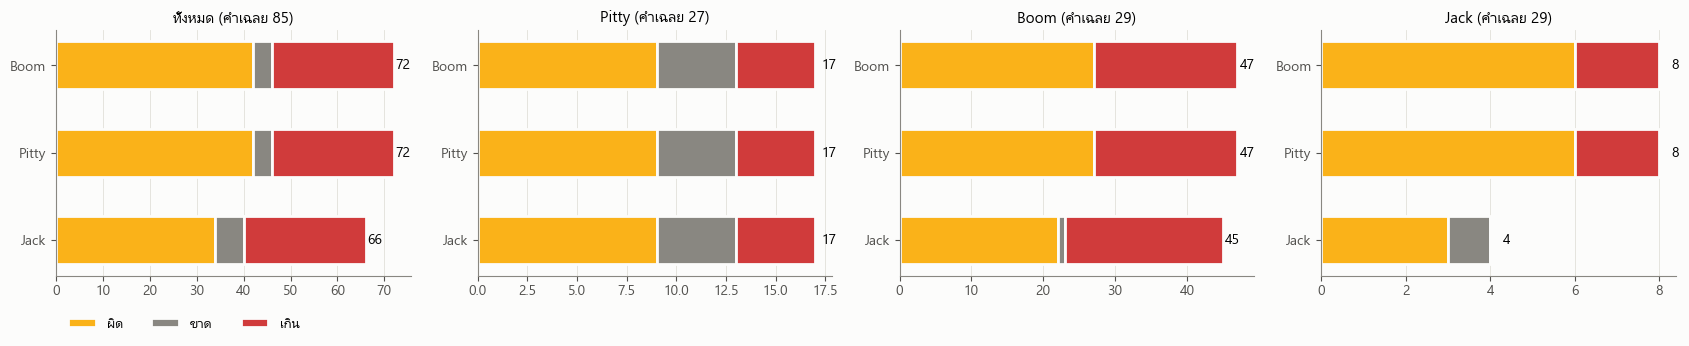

In [11]:
# จำนวนคำที่ผิด / ขาด / เกิน แยกตามคนถ่าย
fig, ax = plt.subplots(1, 4, figsize=(17, 3.6))
for a, p in zip(ax, ['ทั้งหมด', 'Pitty', 'Boom', 'Jack']):
    x_ = V if p == 'ทั้งหมด' else V[V.person == p]
    e = x_.groupby('model')[['wrong', 'missing', 'extra']].sum().reindex(MODELS)
    left = np.zeros(3)
    for k, c, lab in zip(e.columns, ['#fab219', '#898781', '#d03b3b'], ['ผิด', 'ขาด', 'เกิน']):
        a.barh([m.split('-')[0] for m in MODELS], e[k], left=left, color=c, label=lab, height=0.55, edgecolor='#fcfcfb', linewidth=2); left += e[k].values
    for i, v in enumerate(left):
        a.text(v + 0.3, i, int(v), va='center', fontsize=10)
    a.invert_yaxis(); a.set_title(f"{p} (คำเฉลย {x_[x_.model == MODELS[0]].n_ref.sum()})", fontsize=11); a.grid(axis='x', color='#e1e0d9', lw=0.6); a.set_axisbelow(True)
ax[0].legend(frameon=False, ncol=3, loc='upper left', bbox_to_anchor=(0, -0.12)); plt.tight_layout(); plt.show()

---
## 3. Evaluation Report

In [12]:
# ตารางสรุปสุดท้าย: ตัววัดหลักทั้ง 2 ชุดทดสอบ
key = ['WER (เฉลี่ยต่อคลิป)', 'Recall@1', 'Recall@5', 'ยืนยัน precision', 'ยืนยัน coverage', 'count error', 'latency (s, median)']
F = pd.concat({'TSL51 (126 ประโยค)': ST[key + ['Segment F1']], 'team-drive (18 คลิป)': SV[key]}, axis=1)
F.style.format('{:.3f}')

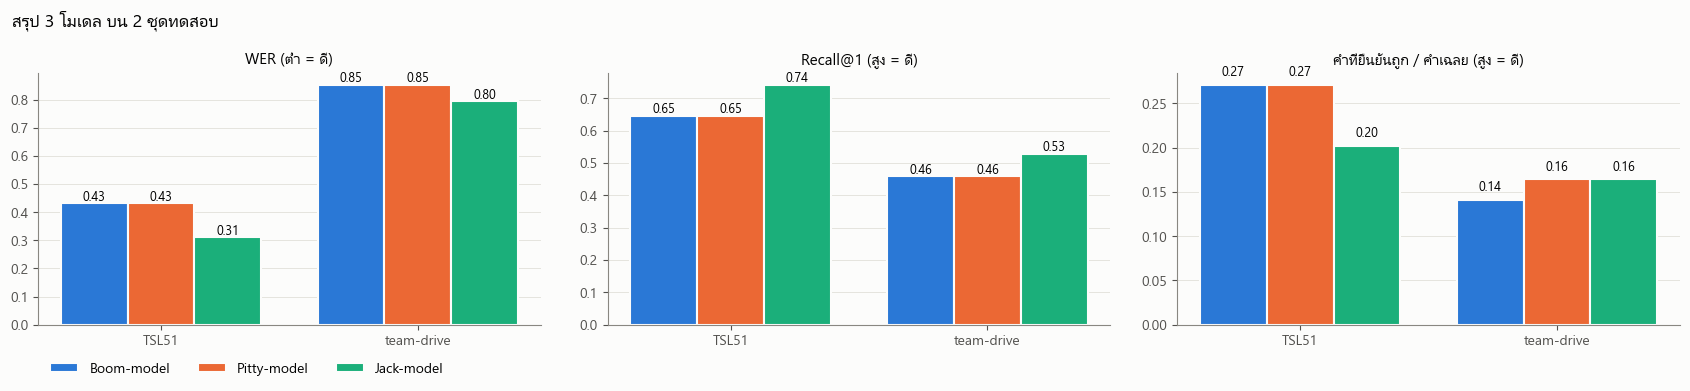

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
sets = [('TSL51', ST), ('team-drive', SV)]
for a, (metric, title, lb) in zip(ax, [('WER (เฉลี่ยต่อคลิป)', 'WER', True), ('Recall@1', 'Recall@1', False), ('ยืนยัน coverage', 'คำที่ยืนยันถูก / คำเฉลย', False)]):
    x = np.arange(2); w = 0.26
    for k, m in enumerate(MODELS):
        v = [t.loc[m, metric] for _, t in sets]
        a.bar(x + (k - 1) * w, v, w, color=COL[m], label=m, edgecolor='#fcfcfb', linewidth=1.5)
        for xi, vi in zip(x + (k - 1) * w, v):
            a.text(xi, vi + 0.01, f'{vi:.2f}', ha='center', fontsize=9)
    a.set_xticks(x); a.set_xticklabels([n for n, _ in sets]); a.set_title(f"{title} ({'ต่ำ' if lb else 'สูง'} = ดี)", fontsize=11)
    a.grid(axis='y', color='#e1e0d9', lw=0.6); a.set_axisbelow(True)
ax[0].legend(frameon=False, ncol=3, loc='upper left', bbox_to_anchor=(0, -0.1))
fig.suptitle('สรุป 3 โมเดล บน 2 ชุดทดสอบ', x=0.01, ha='left', fontsize=13); plt.tight_layout(); plt.show()

In [14]:
# ใครชนะตัววัดไหน + คลิป team-drive ที่แต่ละโมเดลดีที่สุด
best = {}
for name, t, cols in [('TSL51', ST, ['WER (เฉลี่ยต่อคลิป)', 'Recall@1', 'Recall@5', 'Segment F1', 'ยืนยัน precision', 'ยืนยัน coverage']),
                      ('team-drive', SV, ['WER (เฉลี่ยต่อคลิป)', 'Recall@1', 'Recall@5', 'ยืนยัน precision', 'ยืนยัน coverage'])]:
    for c in cols:
        v = t[c].astype(float); b = v.idxmin() if c.startswith('WER') else v.idxmax()
        tie = (v - v[b]).abs().lt(0.0005).sum() > 1
        best[(name, c)] = 'เสมอ' if tie else b
display(pd.Series(best, name='ดีที่สุด').to_frame())
for name, D in [('TSL51', T), ('team-drive', V)]:
    W = D.pivot(index='id', columns='model', values='WER')[MODELS]
    best_tie = {m: int((W[m] <= W.min(1) + 1e-9).sum()) for m in MODELS}
    only = {m: int(W.apply(lambda r: (r == r.min()).sum() == 1 and r.idxmin() == m, axis=1).sum()) for m in MODELS}
    print(f'{name} ({len(W)} คลิป) — WER ต่ำสุดหรือเสมอ:', best_tie, '| ต่ำสุดคนเดียว:', only)

ดีที่สุด
TSL51      WER (เฉลี่ยต่อคลิป)  Jack-model
           Recall@1             Jack-model
           Recall@5             Jack-model
           Segment F1           Jack-model
           ยืนยัน precision     Jack-model
           ยืนยัน coverage            เสมอ
team-drive WER (เฉลี่ยต่อคลิป)  Jack-model
           Recall@1             Jack-model
           Recall@5             Jack-model
           ยืนยัน precision           เสมอ
           ยืนยัน coverage            เสมอ

TSL51 (126 คลิป) — WER ต่ำสุดหรือเสมอ: {'Boom-model': 75, 'Pitty-model': 76, 'Jack-model': 120} | ต่ำสุดคนเดียว: {'Boom-model': 0, 'Pitty-model': 1, 'Jack-model': 49}
team-drive (18 คลิป) — WER ต่ำสุดหรือเสมอ: {'Boom-model': 13, 'Pitty-model': 13, 'Jack-model': 17} | ต่ำสุดคนเดียว: {'Boom-model': 0, 'Pitty-model': 0, 'Jack-model': 5}


### สรุปผล

| | Boom-model | Pitty-model | Jack-model |
|---|---|---|---|
| **TSL51 WER** (126 ประโยค) | 0.431 | 0.433 | **0.310** |
| **TSL51 Recall@1 / Segment F1** | 0.647 / 0.731 | 0.647 / 0.725 | **0.742 / 0.749** |
| **TSL51 คำที่ยืนยัน (ถูก/ทั้งหมด)** | 122/139 (88 %) | 122/139 (88 %) | 91/92 (**99 %**) |
| **team-drive WER** (18 คลิป) | 0.853 | 0.853 | **0.795** |
| **team-drive Recall@1** | 0.459 | 0.459 | **0.529** |

**1. Jack-model ดีที่สุดบนทั้ง 2 ชุด** — TSL51 WER ลด 0.43 → 0.31 (ดีกว่า Pitty-model 50 ประโยค แย่กว่า 6 ประโยค), อ่านคำถูกเพิ่ม 291 → 334 คำ,
คำผิดลด 151 → 100 และคำเกินลด 43 → 27 · มาจาก hand-shape cue (แยกท่าที่ "ท่ามือ" ต่างกันได้ดีขึ้น เช่น ภาษามือ/วิ่ง, คุณ/หนึ่ง) และการรวม/แยกช่วงท่า

**2. Boom-model กับ Pitty-model แทบเหมือนกัน** — น้ำหนักโมเดลเดียวกันทุกไบต์ ต่างแค่ค่า threshold → WER เท่ากัน 122/126 ประโยค (TSL51) และ 18/18 คลิป (team-drive) ต่างกันแค่บางคำ/จำนวนคำที่ยืนยัน

**3. Trade-off ของ Jack-model** — เกณฑ์ยืนยัน 0.8 (อีก 2 โมเดล 0.7) → คำที่ยืนยันแทบไม่ผิดเลย (99 %) แต่ยืนยันได้น้อยกว่า (coverage 0.20 vs 0.27 บน TSL51)
และช้ากว่าเล็กน้อย (~0.95 s vs 0.8–0.9 s ต่อคลิป, CPU)

**4. team-drive แยกตามคน**
* **Jack (5 คลิป)**: Jack-model WER 0.13 vs 0.28 — แต่คลิปชุดนี้เคยใช้รายงานผลตอน v8.1 และเป็นเหตุให้เพิ่มคำ ประเทศ/จีน → เป็น "บ้านตัวเอง" ของ Jack-model
* **Pitty (7 คลิป)**: เท่ากันทั้ง 3 โมเดล (WER ~0.58) — คลิปชุดนี้เคยใช้จูนของ Pitty
* **Boom (6 คลิป)**: WER > 1.5 ทุกโมเดล — คลิปยาว มีช่วงพักที่ถูกอ่านเป็นคำเกิน, 8 จาก 29 คำเฉลยไม่อยู่ใน vocab (ไหม จะ กัน แอบ …) และเฉลยยังไม่ได้ยืนยันลำดับท่า → Jack-model อ่านถูกมากขึ้น (2 → 6 คำ) แต่ยังใช้งานไม่ได้

**ข้อควรระวัง**
* ชุดที่เป็นกลางที่สุดคือ **TSL51 sentence_test** (ไม่มีใครใช้จูน, bank ไม่มีคนในชุดทดสอบ) — แต่เป็นผู้ทำท่าคนเดียว ประโยค template
* team-drive มีแค่ 18 คลิป และทุกชุดย่อยเคยถูกเจ้าของใช้ระหว่างพัฒนา → ใช้ดูแนวโน้ม ไม่ใช่ตัดสินแบบมีนัยสำคัญ
* ปัญหาที่ยังเหลือของทุกโมเดล: **คำเกินจากช่วงพัก/ท่าเปลี่ยน** และ **คำนอก vocab** ในประโยคธรรมชาติ

**สรุป**: ใช้ **Jack-model** เป็นโมเดลหลักของ Part Forward (แม่นที่สุดและคำที่ยืนยันเชื่อถือได้ที่สุด) · ถ้าต้องการให้แสดงคำมากขึ้นค่อยลด accept_min แล้ววัด precision ซ้ำ
